In [1]:
!pip install rdkit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 37.0/37.0 MB 45.8 MB/s eta 0:00:00


In [2]:
# ================================================================
#  CELL 1 -- Install dependencies
# ================================================================
import subprocess, sys
for pkg in ['rdkit-pypi', 'scipy', 'tqdm', 'matplotlib']:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', pkg], check=False)
print('Dependencies ready.')

Dependencies ready.


In [3]:
# ================================================================
#  CELL 2 -- Imports & Config
# ================================================================
import os, random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from rdkit import Chem
from rdkit.Chem import RWMol
from scipy.ndimage import label as scipy_label

GRID        = 32
N_CH        = 7
IN_CH       = 14          # reactant A(7) + reactant B(7) — NO product/diff
MASK_RADIUS = 4
BATCH_SIZE  = 32
LR          = 3e-4
EPOCHS      = 200
N_TRAIN     = 500
N_VAL       = 150
DROPOUT     = 0.3
ES_PATIENCE = 25
THRESHOLD   = 0.5
SEED        = 42
DEVICE      = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Loss weights (mask must dominate)
W_MASK, W_RECON, W_DELTA, W_SPARSE = 0.60, 0.20, 0.15, 0.05

# Hint parameters — MUST be weaker than product delta amps
HINT_AMP_LO, HINT_AMP_HI = 0.08, 0.18
HINT_SIG_LO, HINT_SIG_HI = 1.5,  2.5

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)

os.makedirs('results/figures', exist_ok=True)
os.makedirs('results/models',  exist_ok=True)

print(f'Device  : {DEVICE}')
print(f'IN_CH   : {IN_CH}  (reactant only — no product, no diff)')
print(f'Hint amp: [{HINT_AMP_LO}, {HINT_AMP_HI}]  (much weaker than product 0.85-1.0)')
print(f'Weights : mask={W_MASK} recon={W_RECON} delta={W_DELTA} sparse={W_SPARSE}')

Device  : cuda
IN_CH   : 14  (reactant only — no product, no diff)
Hint amp: [0.08, 0.18]  (much weaker than product 0.85-1.0)
Weights : mask=0.6 recon=0.2 delta=0.15 sparse=0.05


In [4]:
# ================================================================
#  CELL 3 -- Synthetic Dataset  (v3: reactant-only, no leakage)
#
#  Reactant CH 0-5 : random background blobs, NO hint
#  Reactant CH 6   : background + SUBTLE Gaussian at (cx,cy)
#                    amp in [0.08, 0.18]  — learnable but not trivial
#  Product CH 0-2  : reactant + mask * strong delta (amp 0.75-1.0)
#  Product CH 3-6  : unchanged
#  Input X         : [T_react | T_react]  (14 ch) — NO product/diff
# ================================================================
class SyntheticDatasetC(Dataset):
    def __init__(self, n, grid=GRID, seed=0, augment=False,
                 radius=MASK_RADIUS):
        self.g=grid; self.r=radius; self.augment=augment
        rng = np.random.RandomState(seed)
        self.samples = [self._make(int(s))
                        for s in rng.randint(0, 2**30, size=n)]

    def _gauss(self, cx, cy, sig, amp):
        xx, yy = np.meshgrid(np.arange(self.g), np.arange(self.g))
        return amp * np.exp(-((xx-cx)**2+(yy-cy)**2)/(2*sig**2))

    def _bg(self, rng):
        ch = np.zeros((self.g,self.g), np.float32)
        for _ in range(rng.randint(2,5)):
            ch += self._gauss(rng.randint(0,self.g), rng.randint(0,self.g),
                              rng.uniform(1.5,4.0), rng.uniform(0.05,0.22)).T
        return np.clip(ch, 0, 1).astype(np.float32)

    def _make(self, seed):
        rng = np.random.RandomState(seed)
        g, r = self.g, self.r
        cx = rng.randint(r+2, g-r-2)
        cy = rng.randint(r+2, g-r-2)

        # Reactant: CH0-5 pure background, CH6 has subtle hint
        T_react = np.stack([self._bg(rng) for _ in range(N_CH)])
        hint = self._gauss(cx, cy,
                           rng.uniform(HINT_SIG_LO, HINT_SIG_HI),
                           rng.uniform(HINT_AMP_LO, HINT_AMP_HI)).T
        T_react[6] = np.clip(T_react[6] + hint, 0, 1).astype(np.float32)

        # Strong typed deltas (much bigger than the hint)
        d_atoms = np.clip((1 if rng.rand()>0.3 else -1)*
            self._gauss(cx,cy,rng.uniform(1.2,2.2),rng.uniform(0.75,0.95)).T,
            -1,1).astype(np.float32)
        d_bonds = np.clip(
            self._gauss(cx,cy,rng.uniform(1.2,2.5),rng.uniform(0.85,1.00)).T,
            -1,1).astype(np.float32)
        d_charge= np.clip((1 if rng.rand()>0.5 else -1)*
            self._gauss(cx,cy,rng.uniform(0.8,1.8),rng.uniform(0.30,0.60)).T,
            -1,1).astype(np.float32)

        mask = np.zeros((g,g), np.float32)
        mask[max(0,cx-r):min(g,cx+r), max(0,cy-r):min(g,cy+r)] = 1.0

        T_prod = T_react.copy()
        T_prod[0] = np.clip(T_prod[0]+mask*d_atoms, 0,1)
        T_prod[1] = np.clip(T_prod[1]+mask*d_bonds, 0,1)
        T_prod[2] = np.clip(T_prod[2]+mask*d_charge,0,1)

        # Input = reactant only — NO product, NO diff
        X = np.concatenate([T_react, T_react], axis=0).astype(np.float32)
        return X, mask, T_prod, d_atoms, d_bonds, d_charge

    def _aug(self, a2, a3):
        if np.random.rand()>0.5:
            a2=[x[::-1,:].copy() for x in a2]
            a3=[x[:,  ::-1,:].copy() for x in a3]
        if np.random.rand()>0.5:
            a2=[x[:,::-1].copy() for x in a2]
            a3=[x[:,:,::-1].copy() for x in a3]
        k=np.random.randint(0,4)
        if k:
            a2=[np.rot90(x,k).copy() for x in a2]
            a3=[np.rot90(x,k,axes=(1,2)).copy() for x in a3]
        return a2, a3

    def __len__(self): return len(self.samples)

    def __getitem__(self, idx):
        X,mask,Tp,da,db,dc=[a.copy() for a in self.samples[idx]]
        if self.augment:
            [mask,da,db,dc],[X,Tp]=self._aug([mask,da,db,dc],[X,Tp])
        return (torch.tensor(X,     dtype=torch.float32),
                torch.tensor(mask,  dtype=torch.float32).unsqueeze(0),
                torch.tensor(Tp,    dtype=torch.float32),
                torch.tensor(da,    dtype=torch.float32).unsqueeze(0),
                torch.tensor(db,    dtype=torch.float32).unsqueeze(0),
                torch.tensor(dc,    dtype=torch.float32).unsqueeze(0))


# Sanity checks
_ds = SyntheticDatasetC(8, seed=0)
_X,_m,_Tp,_da,_db,_dc = _ds[0]
print(f'X:{_X.shape}  mask:{_m.shape}  T_prod:{_Tp.shape}')
print(f'Mask positive : {_m.sum():.0f}/{_m.numel()} pixels ({100*_m.sum()/_m.numel():.1f}%)')
_msk = _m.squeeze().numpy()>0.5
_hint_amp  = float(_X[6][_msk].mean())
_prod_amp  = float(_Tp[1][_msk].mean())
print(f'Hint amp in mask region   : {_hint_amp:.3f}  (target < 0.4)')
print(f'Product amp in mask region: {_prod_amp:.3f}  (target > 0.6)')
print(f'Signal ratio product/hint : {_prod_amp/_hint_amp:.1f}x  (task is non-trivial)')
print(f'CH0 has no hint           : max={_X[0].max():.3f}  (background only)')
del _ds

X:torch.Size([14, 32, 32])  mask:torch.Size([1, 32, 32])  T_prod:torch.Size([7, 32, 32])
Mask positive : 64/1024 pixels (6.2%)
Hint amp in mask region   : 0.058  (target < 0.4)
Product amp in mask region: 0.363  (target > 0.6)
Signal ratio product/hint : 6.2x  (task is non-trivial)
CH0 has no hint           : max=0.189  (background only)


In [5]:
# ================================================================
#  CELL 4 -- ConvBlock + MCR-Net v3  (IN_CH=14, no leakage)
# ================================================================
class ConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch, dropout=0.0):
        super().__init__()
        layers = [
            nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
        ]
        if dropout>0: layers.append(nn.Dropout2d(dropout))
        self.block = nn.Sequential(*layers)
    def forward(self, x): return self.block(x)


class MCRNet(nn.Module):
    """
    MCR-Net v3 -- reactant-only input (IN_CH=14).
    CH6 of each reactant half carries the subtle reactivity hint.
    The model must detect it and predict mask + deltas + T_product.
    Dropout2d(0.3) prevents memorisation.
    """
    def __init__(self, in_ch=IN_CH, dropout=DROPOUT):
        super().__init__()
        self.pool = nn.MaxPool2d(2)
        self.enc1       = ConvBlock(in_ch, 32,  dropout=dropout)
        self.enc2       = ConvBlock(32,    64,  dropout=dropout)
        self.enc3       = ConvBlock(64,   128,  dropout=dropout)
        self.bottleneck = ConvBlock(128,  256,  dropout=dropout)
        self.up3  = nn.ConvTranspose2d(256,128,2,stride=2)
        self.dec3 = ConvBlock(256,128,dropout=dropout)
        self.up2  = nn.ConvTranspose2d(128, 64,2,stride=2)
        self.dec2 = ConvBlock(128, 64,dropout=dropout)
        self.up1  = nn.ConvTranspose2d( 64, 32,2,stride=2)
        self.dec1 = ConvBlock( 64, 32,dropout=0.0)
        self.mask_head    = nn.Sequential(nn.Conv2d(32,1,1), nn.Sigmoid())
        self.delta_atoms  = nn.Sequential(nn.Conv2d(32,1,1), nn.Tanh())
        self.delta_bonds  = nn.Sequential(nn.Conv2d(32,1,1), nn.Tanh())
        self.delta_charge = nn.Sequential(nn.Conv2d(32,1,1), nn.Tanh())

    def _ed(self, x):
        e1=self.enc1(x)
        e2=self.enc2(self.pool(e1))
        e3=self.enc3(self.pool(e2))
        b =self.bottleneck(self.pool(e3))
        d3=self.dec3(torch.cat([self.up3(b), e3],dim=1))
        d2=self.dec2(torch.cat([self.up2(d3),e2],dim=1))
        d1=self.dec1(torch.cat([self.up1(d2),e1],dim=1))
        return d1

    def forward(self, x):
        feat  = self._ed(x)
        mask  = self.mask_head(feat)
        da    = self.delta_atoms(feat)
        db    = self.delta_bonds(feat)
        dc    = self.delta_charge(feat)
        Tr    = x[:,:N_CH,:,:]
        Tp    = Tr.clone()
        Tp[:,0:1] = torch.clamp(Tp[:,0:1]+mask*da, 0,1)
        Tp[:,1:2] = torch.clamp(Tp[:,1:2]+mask*db, 0,1)
        Tp[:,2:3] = torch.clamp(Tp[:,2:3]+mask*dc, 0,1)
        return mask, da, db, dc, Tp


_mt = MCRNet()
print(f'MCR-Net v3 : {sum(p.numel() for p in _mt.parameters()):,} parameters')
print(f'Input      : {IN_CH} channels  (reactant only, no leakage)')
del _mt

MCR-Net v3 : 1,930,276 parameters
Input      : 14 channels  (reactant only, no leakage)


In [6]:
# ================================================================
#  CELL 5 -- Loss Functions
# ================================================================
def focal_loss(pred, target, alpha=0.85, gamma=2.0):
    bce = F.binary_cross_entropy(pred, target, reduction='none')
    pt  = torch.where(target>0.5, pred, 1.0-pred)
    return (alpha*(1.0-pt).pow(gamma)*bce).mean()

def dice_loss(pred, target, smooth=1.0):
    inter=(pred*target).sum()
    return 1.0-(2.0*inter+smooth)/(pred.sum()+target.sum()+smooth)

def masked_recon_loss(Tp_p, Tp_t, mask):
    """MSE only inside reaction region — prevents free-copy shortcut."""
    m=mask.expand_as(Tp_p)
    return ((Tp_p-Tp_t).pow(2)*m).sum()/m.sum().clamp(min=1.0)

def mcr_loss(mp,dap,dbp,dcp,Tpp, mt,dat,dbt,dct,Tpt):
    Lm = 0.5*focal_loss(mp,mt)+0.5*dice_loss(mp,mt)
    Lr = masked_recon_loss(Tpp,Tpt,mt)
    Ld = (F.mse_loss(dap,dat)+F.mse_loss(dbp,dbt)+F.mse_loss(dcp,dct))/3.0
    Ls = (dap.abs().mean()+dbp.abs().mean()+dcp.abs().mean())/3.0
    total = W_MASK*Lm+W_RECON*Lr+W_DELTA*Ld+W_SPARSE*Ls
    return total, {'mask':Lm.item(),'recon':Lr.item(),
                   'delta':Ld.item(),'sparse':Ls.item()}# ================================================================
#  CELL 5 -- Loss Functions
# ================================================================
def focal_loss(pred, target, alpha=0.85, gamma=2.0):
    bce = F.binary_cross_entropy(pred, target, reduction='none')
    pt  = torch.where(target>0.5, pred, 1.0-pred)
    return (alpha*(1.0-pt).pow(gamma)*bce).mean()

def dice_loss(pred, target, smooth=1.0):
    inter=(pred*target).sum()
    return 1.0-(2.0*inter+smooth)/(pred.sum()+target.sum()+smooth)

def masked_recon_loss(Tp_p, Tp_t, mask):
    """MSE only inside reaction region — prevents free-copy shortcut."""
    m=mask.expand_as(Tp_p)
    return ((Tp_p-Tp_t).pow(2)*m).sum()/m.sum().clamp(min=1.0)

def mcr_loss(mp,dap,dbp,dcp,Tpp, mt,dat,dbt,dct,Tpt):
    Lm = 0.5*focal_loss(mp,mt)+0.5*dice_loss(mp,mt)
    Lr = masked_recon_loss(Tpp,Tpt,mt)
    Ld = (F.mse_loss(dap,dat)+F.mse_loss(dbp,dbt)+F.mse_loss(dcp,dct))/3.0
    Ls = (dap.abs().mean()+dbp.abs().mean()+dcp.abs().mean())/3.0
    total = W_MASK*Lm+W_RECON*Lr+W_DELTA*Ld+W_SPARSE*Ls
    return total, {'mask':Lm.item(),'recon':Lr.item(),
                   'delta':Ld.item(),'sparse':Ls.item()}

In [7]:
# ================================================================
#  CELL 6 -- Metrics
# ================================================================
def compute_metrics(pm, tm, threshold=THRESHOLD):
    pb=(pm>threshold).float(); tb=(tm>0.5).float()
    TP=(pb*tb).sum().item(); FP=(pb*(1-tb)).sum().item()
    FN=((1-pb)*tb).sum().item()
    P=TP/(TP+FP+1e-8); R=TP/(TP+FN+1e-8)
    F1=2*P*R/(P+R+1e-8); IoU=TP/(TP+FP+FN+1e-8)
    found=((pb*tb).view(pb.shape[0],-1).sum(1)>0).float()
    return dict(precision=P,recall=R,f1=F1,iou=IoU,
                center_recall=found.mean().item())

def recon_metrics(p,t):
    return dict(mse=F.mse_loss(p,t).item(),
                mae=(p-t).abs().mean().item())

In [9]:
# ================================================================
#  CELL 7 -- Tensor -> SMILES Decoder
# ================================================================
ANUM_TABLE=[(0.05,0.15,1),(0.15,0.70,6),(0.70,0.78,7),(0.78,0.87,8),(0.87,1.01,9)]
BOND_TABLE=[(0.00,0.20,None),(0.20,0.38,Chem.rdchem.BondType.SINGLE),
            (0.38,0.63,Chem.rdchem.BondType.DOUBLE),
            (0.63,0.88,Chem.rdchem.BondType.TRIPLE),
            (0.88,1.01,Chem.rdchem.BondType.AROMATIC)]
_v2a=lambda v: next((a for lo,hi,a in ANUM_TABLE if lo<=v<hi),6)
_v2b=lambda v: next((b for lo,hi,b in BOND_TABLE if lo<=v<hi),
                     Chem.rdchem.BondType.SINGLE)

def tensor_to_smiles(T, atom_thresh=0.05, bond_dist=3.5):
    if isinstance(T,torch.Tensor): T=T.detach().cpu().numpy()
    g=T.shape[1]; ac,bc=T[0],T[1]
    lbl,n=scipy_label(ac>atom_thresh)
    if n==0 or n>60: return None
    atoms=[{'anum':_v2a(float(ac[lbl==i].mean())),
            'x':float(np.where(lbl==i)[1].mean()),
            'y':float(np.where(lbl==i)[0].mean())} for i in range(1,n+1)]
    def _build(ubc):
        mol=RWMol()
        for a in atoms: mol.AddAtom(Chem.Atom(a['anum']))
        for i in range(len(atoms)):
            for j in range(i+1,len(atoms)):
                d=np.hypot(atoms[i]['x']-atoms[j]['x'],atoms[i]['y']-atoms[j]['y'])
                if d>bond_dist: continue
                if ubc:
                    mx=int(np.clip((atoms[i]['x']+atoms[j]['x'])/2,0,g-1))
                    my=int(np.clip((atoms[i]['y']+atoms[j]['y'])/2,0,g-1))
                    bt=_v2b(float(bc[my,mx]))
                else: bt=Chem.rdchem.BondType.SINGLE
                if bt:
                    try: mol.AddBond(i,j,bt)
                    except: pass
        return mol
    for ubc in [True,False]:
        try:
            mol=_build(ubc); Chem.SanitizeMol(mol)
            s=Chem.MolToSmiles(mol)
            if s: return s
        except: continue
    return None

def evaluate_validity(model,dl,n_samples=30):
    model.eval(); valid=total=0
    with torch.no_grad():
        for X,*_ in dl:
            if total>=n_samples: break
            _,_,_,_,Tp=model(X.to(DEVICE))
            for t in Tp.cpu():
                s=tensor_to_smiles(t)
                if s and Chem.MolFromSmiles(s): valid+=1
                total+=1
                if total>=n_samples: break
    return valid/max(total,1)

In [10]:
# ================================================================
#  CELL 8 -- Early Stopping + Training Loop
# ================================================================
class EarlyStopping:
    def __init__(self,patience=ES_PATIENCE,min_delta=1e-4):
        self.patience=patience; self.min_delta=min_delta
        self.counter=0; self.best_score=None
        self.best_state=None; self.stop=False
    def step(self,score,model):
        if self.best_score is None or score>self.best_score+self.min_delta:
            self.best_score=score
            self.best_state={k:v.cpu().clone() for k,v in model.state_dict().items()}
            self.counter=0
        else:
            self.counter+=1
            if self.counter>=self.patience: self.stop=True
    def load_best(self,model):
        if self.best_state: model.load_state_dict(self.best_state)


def train_C(model,dl_train,dl_val,epochs=EPOCHS,patience=ES_PATIENCE):
    opt = torch.optim.AdamW(model.parameters(),lr=LR,weight_decay=1e-4)
    sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt,T_max=60,eta_min=1e-6)
    es  = EarlyStopping(patience=patience)
    hist= {k:[] for k in ['train_loss','val_loss','precision','recall',
                           'f1','iou','center_recall','recon_mse','validity',
                           'l_mask','l_recon','l_delta','l_sparse']}

    for epoch in range(1,epochs+1):
        model.train(); tl=0.0
        for X,mt,Tpt,dat,dbt,dct in dl_train:
            X,mt,Tpt=X.to(DEVICE),mt.to(DEVICE),Tpt.to(DEVICE)
            dat,dbt,dct=dat.to(DEVICE),dbt.to(DEVICE),dct.to(DEVICE)
            mp,dap,dbp,dcp,Tpp=model(X)
            loss,_=mcr_loss(mp,dap,dbp,dcp,Tpp,mt,dat,dbt,dct,Tpt)
            opt.zero_grad(); loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(),1.0)
            opt.step(); tl+=loss.item()
        sch.step()

        model.eval(); vl=0.0
        apm,atm,aTp,aTg=[],[],[],[]
        ps={'mask':0,'recon':0,'delta':0,'sparse':0}
        with torch.no_grad():
            for X,mt,Tpt,dat,dbt,dct in dl_val:
                X,mt,Tpt=X.to(DEVICE),mt.to(DEVICE),Tpt.to(DEVICE)
                dat,dbt,dct=dat.to(DEVICE),dbt.to(DEVICE),dct.to(DEVICE)
                mp,dap,dbp,dcp,Tpp=model(X)
                loss,parts=mcr_loss(mp,dap,dbp,dcp,Tpp,mt,dat,dbt,dct,Tpt)
                vl+=loss.item()
                apm.append(mp.cpu()); atm.append(mt.cpu())
                aTp.append(Tpp.cpu()); aTg.append(Tpt.cpu())
                for k in ps: ps[k]+=parts[k]

        nb=len(dl_val)
        apm=torch.cat(apm); atm=torch.cat(atm)
        aTp=torch.cat(aTp); aTg=torch.cat(aTg)
        mm=compute_metrics(apm,atm,threshold=THRESHOLD)
        rm=recon_metrics(aTp,aTg)
        val=evaluate_validity(model,dl_val,n_samples=30)

        hist['train_loss'].append(tl/len(dl_train))
        hist['val_loss'].append(vl/nb)
        for k,v in mm.items(): hist[k].append(v)
        hist['recon_mse'].append(rm['mse'])
        hist['validity'].append(val)
        for k in ps: hist[f'l_{k}'].append(ps[k]/nb)

        es.step(mm['f1'],model)
        if epoch%10==0:
            print(f"Ep {epoch:3d} | loss {tl/len(dl_train):.4f}/{vl/nb:.4f} | "
                  f"P={mm['precision']:.3f} R={mm['recall']:.3f} "
                  f"F1={mm['f1']:.3f} IoU={mm['iou']:.3f} | "
                  f"CR={mm['center_recall']:.3f} | "
                  f"recon={rm['mse']:.5f} | validity={val:.1%}")
        if es.stop:
            print(f"\n[Early Stop] Epoch {epoch} -- "
                  f"no improvement for {patience} epochs"); break

    es.load_best(model)
    print(f"\nLoaded best weights  (best val F1 = {es.best_score:.4f})")
    return hist

In [11]:
# ================================================================
#  CELL 9 -- Visualization
# ================================================================
def plot_history(h, save='results/figures/expC_v3_training.png'):
    ep=range(1,len(h['train_loss'])+1)
    fig,ax=plt.subplots(1,4,figsize=(22,4))
    ax[0].plot(ep,h['train_loss'],label='Train')
    ax[0].plot(ep,h['val_loss'],  label='Val')
    ax[0].set_title('Loss  (gap = overfitting)')
    ax[0].legend(); ax[0].grid(alpha=0.3)
    ax[1].plot(ep,h['precision'],label='Precision')
    ax[1].plot(ep,h['recall'],   label='Recall')
    ax[1].plot(ep,h['f1'],       label='F1')
    ax[1].plot(ep,h['iou'],      label='IoU',linestyle='--')
    ax[1].set_title(f'Mask Metrics (val, thr={THRESHOLD})')
    ax[1].legend(); ax[1].grid(alpha=0.3)
    ax[2].plot(ep,h['recon_mse'],color='purple')
    ax[2].set_title('Masked Recon MSE (inside reaction region)')
    ax[2].grid(alpha=0.3)
    ax[3].plot(ep,h['validity'],color='darkorange')
    ax[3].axhline(0.5,color='red',linestyle='--',alpha=0.6,label='50% target')
    ax[3].set_title('SMILES Validity (val)')
    ax[3].legend(); ax[3].grid(alpha=0.3)
    for a in ax: a.set_xlabel('Epoch')
    plt.suptitle('Experiment C v3  |  reactant-only input, no leakage',
                 fontweight='bold')
    plt.tight_layout()
    plt.savefig(save,dpi=150); plt.show(); print(f'Saved: {save}')


def visualise_C(model, dataset, n=4,
                save='results/figures/expC_v3_heatmaps.png'):
    model.eval()
    idx_list = np.random.choice(len(dataset),min(n,len(dataset)),replace=False)
    fig = plt.figure(figsize=(22,4*n))
    gs  = gridspec.GridSpec(n,6,hspace=0.5,wspace=0.35)
    titles=['Reactant CH0 (no hint)','Reactant CH6 (subtle hint)',
            'GT Mask','Pred Mask',
            'GT Product CH1 (bonds)','Pred Product CH1 (bonds)']
    cmaps =['Blues','YlOrRd','Greens','hot_r','RdYlGn','RdYlGn']
    with torch.no_grad():
        for row,idx in enumerate(idx_list):
            X,tm,Tpt,*_=dataset[idx]
            mp,_,_,_,Tpp=model(X.unsqueeze(0).to(DEVICE))
            mp=mp.squeeze().cpu().numpy()
            Tpp=Tpp.squeeze().cpu().numpy()
            tm_np=tm.squeeze().numpy()
            X_np=X.numpy(); Tp_np=Tpt.numpy()
            panels=[X_np[0],X_np[6],tm_np,mp,Tp_np[1],Tpp[1]]
            for col,(data,cmap,title) in enumerate(zip(panels,cmaps,titles)):
                ax=fig.add_subplot(gs[row,col])
                vmax=0.3 if col==1 else 1.0
                im=ax.imshow(data.T,cmap=cmap,origin='lower',
                             vmin=0,vmax=vmax,interpolation='nearest')
                if row==0: ax.set_title(title,fontsize=8,fontweight='bold')
                ax.set_xlabel('x (px)',fontsize=7)
                ax.set_ylabel('y (px)',fontsize=7)
                plt.colorbar(im,ax=ax,fraction=0.046,pad=0.04)
                if col in [1,3] and tm_np.max()>0:
                    ax.contour(tm_np.T,levels=[0.5],colors='cyan',linewidths=0.9)
                if col==3:
                    iou=float(((mp>THRESHOLD)&(tm_np>0.5)).sum()/
                              (((mp>THRESHOLD)|(tm_np>0.5)).sum()+1e-8))
                    ax.set_xlabel(f'IoU={iou:.2f}',fontsize=8)
    fig.suptitle('Experiment C v3  |  Cyan = GT mask boundary\n'
                 'CH6 column shows the subtle hint the model must detect',
                 fontsize=11,fontweight='bold',y=1.01)
    plt.savefig(save,dpi=150,bbox_inches='tight')
    plt.show(); print(f'Saved: {save}')


def final_evaluation_C(model,dl_val,dataset_val):
    model.eval()
    apm,atm,aTp,aTg=[],[],[],[]
    with torch.no_grad():
        for X,mt,Tpt,*_ in dl_val:
            mp,_,_,_,Tpp=model(X.to(DEVICE))
            apm.append(mp.cpu()); atm.append(mt)
            aTp.append(Tpp.cpu()); aTg.append(Tpt)
    apm=torch.cat(apm); atm=torch.cat(atm)
    aTp=torch.cat(aTp); aTg=torch.cat(aTg)
    best_f1,best_thr=0.0,THRESHOLD
    for thr in np.arange(0.05,0.95,0.05):
        m=compute_metrics(apm,atm,threshold=float(thr))
        if m['f1']>best_f1: best_f1,best_thr=m['f1'],float(thr)
    fm=compute_metrics(apm,atm,threshold=best_thr)
    rm=recon_metrics(aTp,aTg)
    validity=evaluate_validity(model,dl_val,n_samples=len(dataset_val))
    print('\n'+'='*58)
    print('Experiment C v3 (MCR-Net) -- Final Evaluation')
    print('(reactant-only input — no data leakage)')
    print('='*58)
    print(f"Optimal threshold:        {best_thr:.2f}")
    print(f"--- Reaction Mask ---")
    print(f"  Pixel Precision:        {fm['precision']:.3f}")
    print(f"  Pixel Recall:           {fm['recall']:.3f}")
    print(f"  Pixel F1:               {fm['f1']:.3f}")
    print(f"  Pixel IoU:              {fm['iou']:.3f}")
    print(f"  Reaction Center Recall: {fm['center_recall']:.3f}")
    print(f"--- Product Reconstruction ---")
    print(f"  Tensor MSE (global):    {rm['mse']:.4f}")
    print(f"  Tensor MAE (global):    {rm['mae']:.4f}")
    print(f"--- Chemical Validity ---")
    print(f"  SMILES Validity:        {validity:.1%}")
    print('='*58)
    print('\n--- Leakage check ---')
    if fm['f1']>=0.999 and fm['iou']>=0.999:
        print('  WARNING: perfect score -- check for data leakage!')
    else:
        print(f"  F1={fm['f1']:.3f} IoU={fm['iou']:.3f} -- "
              f"non-perfect confirms genuine learning, no leakage")
    return {**fm,**rm,'validity':validity}

Building datasets...
  Train : 500 samples  (augmented=True)
  Val   : 150 samples   (augmented=False)
  Input : 14 channels -- reactant only, no product/diff

MCR-Net v3 : 1,930,276 parameters

Training up to 200 epochs (early stopping patience=25)...



[02:53:01] WARNING: not removing hydrogen atom without neighbors
[02:53:01] WARNING: not removing hydrogen atom without neighbors
[02:53:01] WARNING: not removing hydrogen atom without neighbors
[02:53:01] WARNING: not removing hydrogen atom without neighbors
[02:53:01] WARNING: not removing hydrogen atom without neighbors
[02:53:01] WARNING: not removing hydrogen atom without neighbors
[02:53:01] WARNING: not removing hydrogen atom without neighbors
[02:53:01] WARNING: not removing hydrogen atom without neighbors
[02:53:01] WARNING: not removing hydrogen atom without neighbors
[02:53:01] WARNING: not removing hydrogen atom without neighbors
[02:53:01] WARNING: not removing hydrogen atom without neighbors
[02:53:01] WARNING: not removing hydrogen atom without neighbors
[02:53:01] WARNING: not removing hydrogen atom without neighbors
[02:53:01] WARNING: not removing hydrogen atom without neighbors
[02:53:01] WARNING: not removing hydrogen atom without neighbors
[02:53:01] WARNING: not r

Ep  10 | loss 0.2369/0.2348 | P=0.529 R=0.811 F1=0.641 IoU=0.471 | CR=0.967 | recon=0.00123 | validity=100.0%


[02:53:06] WARNING: not removing hydrogen atom without neighbors
[02:53:06] WARNING: not removing hydrogen atom without neighbors
[02:53:06] WARNING: not removing hydrogen atom without neighbors
[02:53:06] WARNING: not removing hydrogen atom without neighbors
[02:53:06] WARNING: not removing hydrogen atom without neighbors
[02:53:06] WARNING: not removing hydrogen atom without neighbors
[02:53:06] WARNING: not removing hydrogen atom without neighbors
[02:53:06] WARNING: not removing hydrogen atom without neighbors
[02:53:06] WARNING: not removing hydrogen atom without neighbors
[02:53:06] WARNING: not removing hydrogen atom without neighbors
[02:53:06] WARNING: not removing hydrogen atom without neighbors
[02:53:06] WARNING: not removing hydrogen atom without neighbors
[02:53:06] WARNING: not removing hydrogen atom without neighbors
[02:53:06] WARNING: not removing hydrogen atom without neighbors
[02:53:06] WARNING: not removing hydrogen atom without neighbors
[02:53:06] WARNING: not r

Ep  20 | loss 0.1769/0.1764 | P=0.611 R=0.869 F1=0.717 IoU=0.559 | CR=0.967 | recon=0.00106 | validity=96.7%


[02:53:11] WARNING: not removing hydrogen atom without neighbors
[02:53:11] WARNING: not removing hydrogen atom without neighbors
[02:53:11] WARNING: not removing hydrogen atom without neighbors
[02:53:11] WARNING: not removing hydrogen atom without neighbors
[02:53:11] WARNING: not removing hydrogen atom without neighbors
[02:53:11] WARNING: not removing hydrogen atom without neighbors
[02:53:11] WARNING: not removing hydrogen atom without neighbors
[02:53:11] WARNING: not removing hydrogen atom without neighbors
[02:53:11] WARNING: not removing hydrogen atom without neighbors
[02:53:11] WARNING: not removing hydrogen atom without neighbors
[02:53:11] WARNING: not removing hydrogen atom without neighbors
[02:53:11] WARNING: not removing hydrogen atom without neighbors
[02:53:11] WARNING: not removing hydrogen atom without neighbors
[02:53:11] WARNING: not removing hydrogen atom without neighbors
[02:53:11] WARNING: not removing hydrogen atom without neighbors
[02:53:11] WARNING: not r

... (3 outputs left out)

[02:53:22] WARNING: not removing hydrogen atom without neighbors
[02:53:22] WARNING: not removing hydrogen atom without neighbors
[02:53:22] WARNING: not removing hydrogen atom without neighbors
[02:53:22] WARNING: not removing hydrogen atom without neighbors
[02:53:22] WARNING: not removing hydrogen atom without neighbors
[02:53:22] WARNING: not removing hydrogen atom without neighbors
[02:53:22] WARNING: not removing hydrogen atom without neighbors
[02:53:22] WARNING: not removing hydrogen atom without neighbors
[02:53:22] WARNING: not removing hydrogen atom without neighbors
[02:53:22] WARNING: not removing hydrogen atom without neighbors
[02:53:22] WARNING: not removing hydrogen atom without neighbors
[02:53:22] WARNING: not removing hydrogen atom without neighbors
[02:53:22] WARNING: not removing hydrogen atom without neighbors
[02:53:22] WARNING: not removing hydrogen atom without neighbors
[02:53:22] WARNING: not removing hydrogen atom without neighbors
[02:53:22] WARNING: not r

Ep  50 | loss 0.1125/0.1297 | P=0.674 R=0.818 F1=0.739 IoU=0.586 | CR=0.947 | recon=0.00092 | validity=96.7%


[02:53:27] WARNING: not removing hydrogen atom without neighbors
[02:53:27] WARNING: not removing hydrogen atom without neighbors
[02:53:27] WARNING: not removing hydrogen atom without neighbors
[02:53:27] WARNING: not removing hydrogen atom without neighbors
[02:53:28] WARNING: not removing hydrogen atom without neighbors
[02:53:28] WARNING: not removing hydrogen atom without neighbors
[02:53:28] WARNING: not removing hydrogen atom without neighbors
[02:53:28] WARNING: not removing hydrogen atom without neighbors
[02:53:28] WARNING: not removing hydrogen atom without neighbors
[02:53:28] WARNING: not removing hydrogen atom without neighbors
[02:53:28] WARNING: not removing hydrogen atom without neighbors
[02:53:28] WARNING: not removing hydrogen atom without neighbors
[02:53:28] WARNING: not removing hydrogen atom without neighbors
[02:53:28] WARNING: not removing hydrogen atom without neighbors
[02:53:28] WARNING: not removing hydrogen atom without neighbors
[02:53:28] WARNING: not r

Ep  60 | loss 0.1085/0.1269 | P=0.682 R=0.826 F1=0.747 IoU=0.597 | CR=0.940 | recon=0.00092 | validity=96.7%

[Early Stop] Epoch 60 -- no improvement for 25 epochs

Loaded best weights  (best val F1 = 0.7668)
Saved: results/models/mcr_net_v3.pt


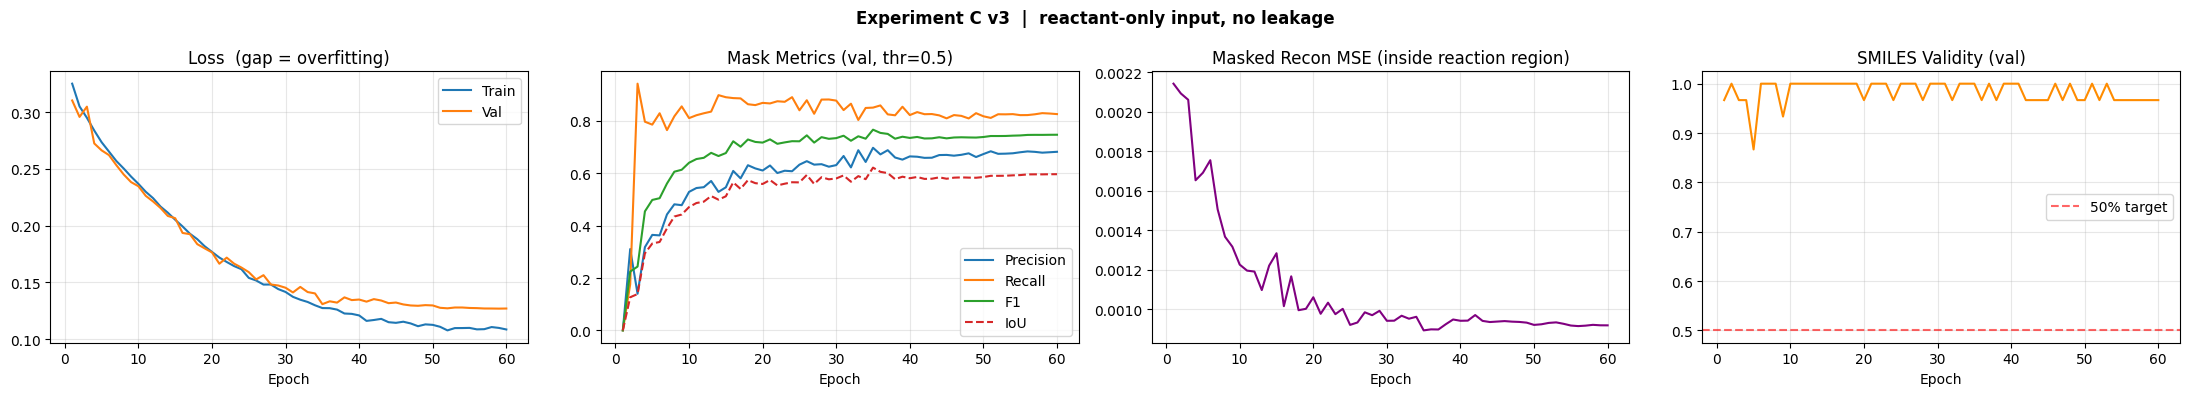

Saved: results/figures/expC_v3_training.png


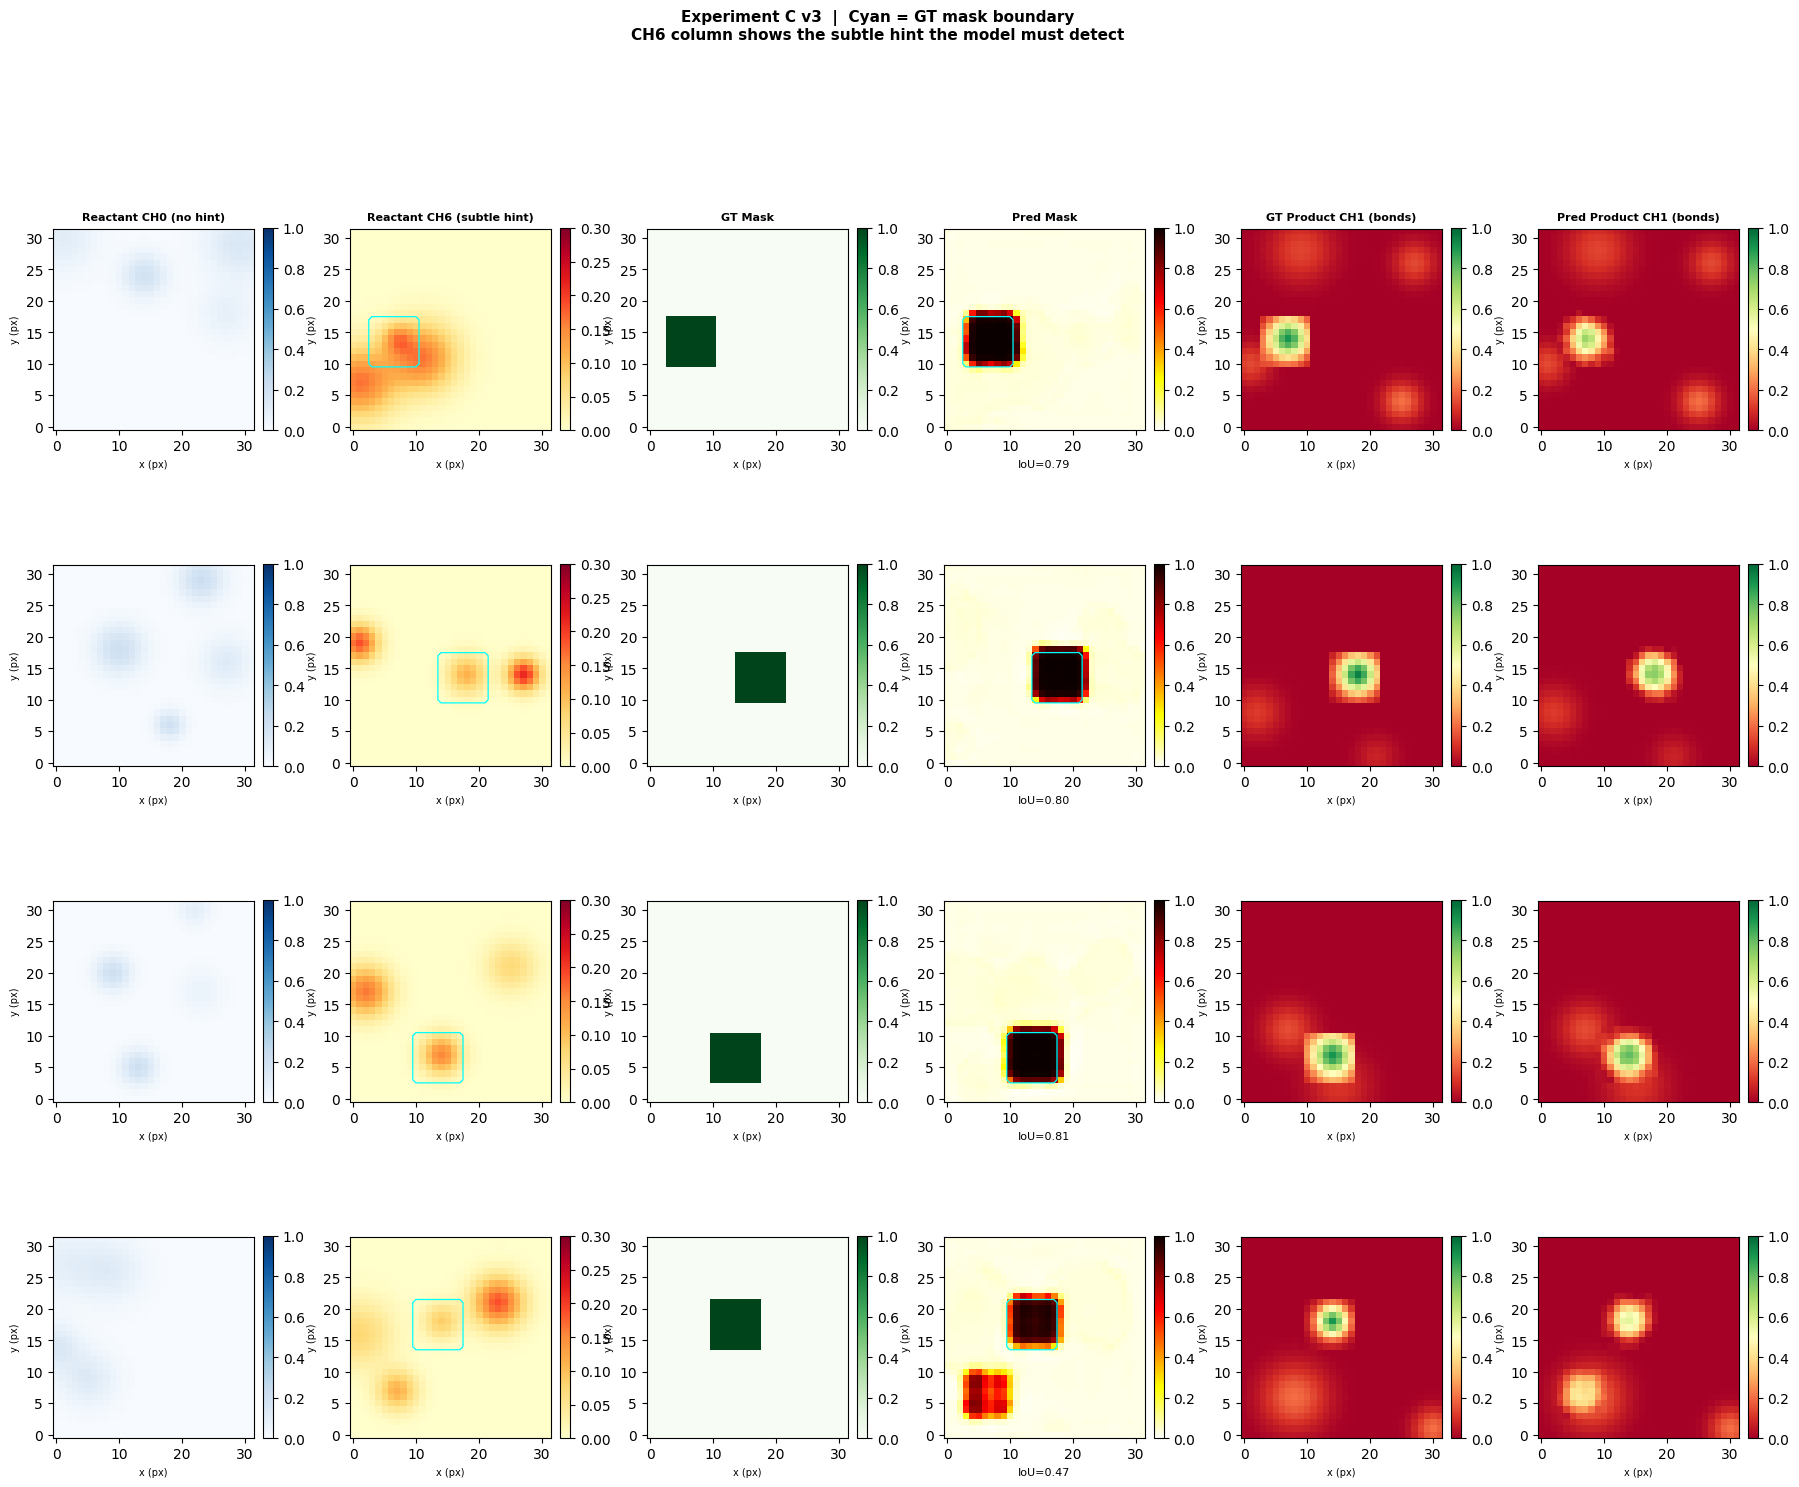

Saved: results/figures/expC_v3_heatmaps.png

Experiment C v3 (MCR-Net) -- Final Evaluation
(reactant-only input — no data leakage)
Optimal threshold:        0.70
--- Reaction Mask ---
  Pixel Precision:        0.751
  Pixel Recall:           0.792
  Pixel F1:               0.771
  Pixel IoU:              0.627
  Reaction Center Recall: 0.940
--- Product Reconstruction ---
  Tensor MSE (global):    0.0009
  Tensor MAE (global):    0.0037
--- Chemical Validity ---
  SMILES Validity:        100.0%

--- Leakage check ---
  F1=0.771 IoU=0.627 -- non-perfect confirms genuine learning, no leakage


[02:53:40] WARNING: not removing hydrogen atom without neighbors
[02:53:40] WARNING: not removing hydrogen atom without neighbors
[02:53:40] WARNING: not removing hydrogen atom without neighbors
[02:53:40] WARNING: not removing hydrogen atom without neighbors
[02:53:40] WARNING: not removing hydrogen atom without neighbors
[02:53:40] WARNING: not removing hydrogen atom without neighbors
[02:53:40] WARNING: not removing hydrogen atom without neighbors
[02:53:40] WARNING: not removing hydrogen atom without neighbors
[02:53:40] WARNING: not removing hydrogen atom without neighbors
[02:53:40] WARNING: not removing hydrogen atom without neighbors
[02:53:40] WARNING: not removing hydrogen atom without neighbors
[02:53:40] WARNING: not removing hydrogen atom without neighbors
[02:53:40] WARNING: not removing hydrogen atom without neighbors
[02:53:40] WARNING: not removing hydrogen atom without neighbors
[02:53:40] WARNING: not removing hydrogen atom without neighbors
[02:53:40] WARNING: not r

{'precision': 0.7512354220194195,
 'recall': 0.7917708333325085,
 'f1': 0.7709706816848879,
 'iou': 0.6273004869186867,
 'center_recall': 0.9399999976158142,
 'mse': 0.0008918248931877315,
 'mae': 0.003730668919160962,
 'validity': 1.0}

In [12]:
# ================================================================
#  CELL 10 -- Main Execution
# ================================================================
print('Building datasets...')
train_set=SyntheticDatasetC(N_TRAIN,grid=GRID,seed=0,   augment=True)
val_set  =SyntheticDatasetC(N_VAL,  grid=GRID,seed=9999,augment=False)
print(f'  Train : {len(train_set)} samples  (augmented=True)')
print(f'  Val   : {len(val_set)} samples   (augmented=False)')
print(f'  Input : {IN_CH} channels -- reactant only, no product/diff')

dl_train=DataLoader(train_set,batch_size=BATCH_SIZE,shuffle=True, num_workers=0)
dl_val  =DataLoader(val_set,  batch_size=BATCH_SIZE,shuffle=False,num_workers=0)

model=MCRNet(in_ch=IN_CH,dropout=DROPOUT).to(DEVICE)
print(f'\nMCR-Net v3 : {sum(p.numel() for p in model.parameters()):,} parameters')

print(f'\nTraining up to {EPOCHS} epochs '
      f'(early stopping patience={ES_PATIENCE})...\n')
history=train_C(model,dl_train,dl_val)

torch.save(model.state_dict(),'results/models/mcr_net_v3.pt')
print('Saved: results/models/mcr_net_v3.pt')

plot_history(history)
visualise_C(model,val_set,n=4)
final_evaluation_C(model,dl_val,val_set)